<div style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; color: #1a1a1a; max-width: 800px; margin: 0 auto; line-height: 1.6;">
<h1 style="font-size: 3.2em; font-weight: 700; margin-bottom: 25px; color: #111; letter-spacing: -0.5px;">Pima Indians Diabetes Prediction</h1>
<div style="font-size: 0.95em; color: #555; margin-bottom: 20px;">
<strong>Author:</strong> G.M. Noor-Ul Islam Labib &nbsp;|&nbsp; <strong>Dataset:</strong> <a href="https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database" style="color: #0066cc; text-decoration: none; font-weight: 500;">Pima Indians Diabetes Database</a> &nbsp;|&nbsp; <strong>Source:</strong> NIDDK
</div>
<hr style="border: 0; height: 1px; background: #e5e5e5; margin: 20px 0;" />
<h2 style="font-size: 1.3em; font-weight: 600; margin-bottom: 10px; color: #111; border-bottom: 2px solid #eee; padding-bottom: 5px;">Dataset Context</h2>
<p style="font-size: 1em; color: #444; margin-bottom: 15px;">This project uses the <strong>Pima Indians Diabetes Database</strong>, originally sourced from the National Institute of Diabetes and Digestive and Kidney Diseases. It contains diagnostic records for <strong>768 female patients</strong> of Pima Indian heritage (aged 21 and older), described across <strong>8 medical predictor variables</strong>. The dataset is a classic benchmark for practicing exploratory data analysis, handling implicit missing values, and building classification pipelines.</p>
<p style="font-size: 1em; color: #444; margin-bottom: 50px;">Each patient's profile is composed of distinct medical domains: general demographics and history, metabolic indicators, physical body measurements, and genetic risk factors. Together, these features capture the key biological indicators used to diagnostically predict the onset of diabetes.</p>
<h2 style="font-size: 1.3em; font-weight: 600; margin-bottom: 15px; color: #111; border-bottom: 2px solid #eee; padding-bottom: 5px;">Feature Domains</h2>
<div style="margin-bottom: 25px;">
<div style="background: #f9f9f9; border: 1px solid #e5e5e5; border-left: 4px solid #ccc; padding: 12px 15px; margin-bottom: 10px; border-radius: 4px;">
<strong style="display: block; font-size: 1em; color: #111; margin-bottom: 3px;">Demographics & History</strong>
<span style="font-size: 0.95em; color: #555;">Patient age (years) and total number of pregnancies.</span>
</div>
<div style="background: #f9f9f9; border: 1px solid #e5e5e5; border-left: 4px solid #ccc; padding: 12px 15px; margin-bottom: 10px; border-radius: 4px;">
<strong style="display: block; font-size: 1em; color: #111; margin-bottom: 3px;">Metabolic Indicators</strong>
<span style="font-size: 0.95em; color: #555;">Plasma glucose concentration (2-hour oral tolerance test) and 2-Hour serum insulin levels.</span>
</div>
<div style="background: #f9f9f9; border: 1px solid #e5e5e5; border-left: 4px solid #ccc; padding: 12px 15px; margin-bottom: 10px; border-radius: 4px;">
<strong style="display: block; font-size: 1em; color: #111; margin-bottom: 3px;">Physical Measurements</strong>
<span style="font-size: 0.95em; color: #555;">Body Mass Index (BMI), diastolic blood pressure (mm Hg), and triceps skin fold thickness (mm).</span>
</div>
<div style="background: #f9f9f9; border: 1px solid #e5e5e5; border-left: 4px solid #ccc; padding: 12px 15px; margin-bottom: 10px; border-radius: 4px;">
<strong style="display: block; font-size: 1em; color: #111; margin-bottom: 3px;">Genetic Risk</strong>
<span style="font-size: 0.95em; color: #555;">Diabetes Pedigree Function (a formulated score representing the likelihood of diabetes based on family history).</span>
</div>
</div>
<h2 style="font-size: 1.3em; font-weight: 600; margin-bottom: 10px; color: #111; border-bottom: 2px solid #eee; padding-bottom: 5px;">Target Objective</h2>
<p style="font-size: 1em; color: #444; margin-bottom: 20px;">The goal is to accurately predict the <code style="background: #f5f5f5; border: 1px solid #ddd; padding: 2px 6px; border-radius: 4px; font-family: monospace; color: #111; font-size: 0.9em;">Outcome</code> column — a binary classification target (1 for diabetes, 0 for negative). We will evaluate models like K-Nearest Neighbors against Logistic Regression, handling data nuances like zero-imputation for biological metrics, and focusing heavily on evaluating Precision and Recall to counteract the dataset's class imbalance.</p>
<hr style="border: 0; height: 1px; background: #e5e5e5; margin: 20px 0;" />
<p style="font-size: 0.9em; color: #555;"><strong>Dataset Link:</strong> <a href="https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database" style="color: #0066cc; text-decoration: none; font-weight: 500;">Pima Indians Diabetes on Kaggle</a></p>
</div>

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/organizations/uciml/pima-indians-diabetes-database/diabetes.csv


# Step-1: Import Necessary Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer

from sklearn.compose import ColumnTransformer


from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer


from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV



from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

from sklearn.linear_model import LogisticRegression


from mlxtend.plotting import plot_decision_regions

from sklearn.neighbors import KNeighborsClassifier



# Step-2: Understanding The Data

In [3]:
file_path="/kaggle/input/datasets/organizations/uciml/pima-indians-diabetes-database/diabetes.csv"
df=pd.read_csv(file_path)

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.sample(5)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
173,1,79,60,42,48,43.5,0.678,23,0
325,1,157,72,21,168,25.6,0.123,24,0
681,0,162,76,36,0,49.6,0.364,26,1
317,3,182,74,0,0,30.5,0.345,29,1
1,1,85,66,29,0,26.6,0.351,31,0


In [6]:
df.shape

(768, 9)

In [7]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [8]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

# Step-3: Exploratory Data Analysis

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


**Here the minimum value of 'Glucose','BloodPressure','SkinThickness','Insulin','BMI' can not be zero.  So we can confirm that these are the missing values.**

In [11]:
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]]=df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0,np.nan)

In [12]:
df.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

<Axes: xlabel='Outcome', ylabel='count'>

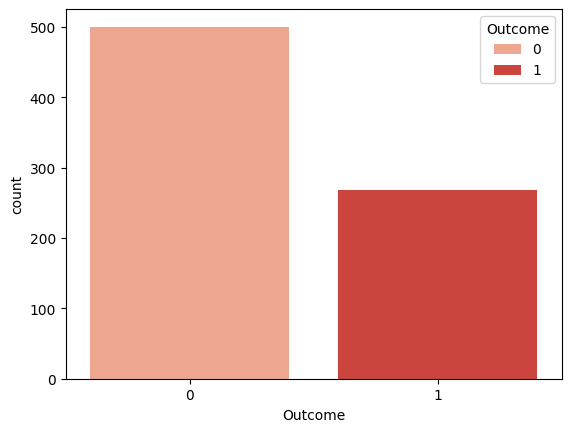

In [13]:
sns.countplot(data=df,x="Outcome",hue="Outcome",palette="Reds")

In [14]:
df["Outcome"].value_counts(normalize=True)

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

**Considering the Outcomes,the dataset is moderately imbalanced.So F1 score would be a better metric than accuracy for this dataset**

In [15]:
columns=df.columns.to_list()

In [16]:
columns.remove("Outcome")

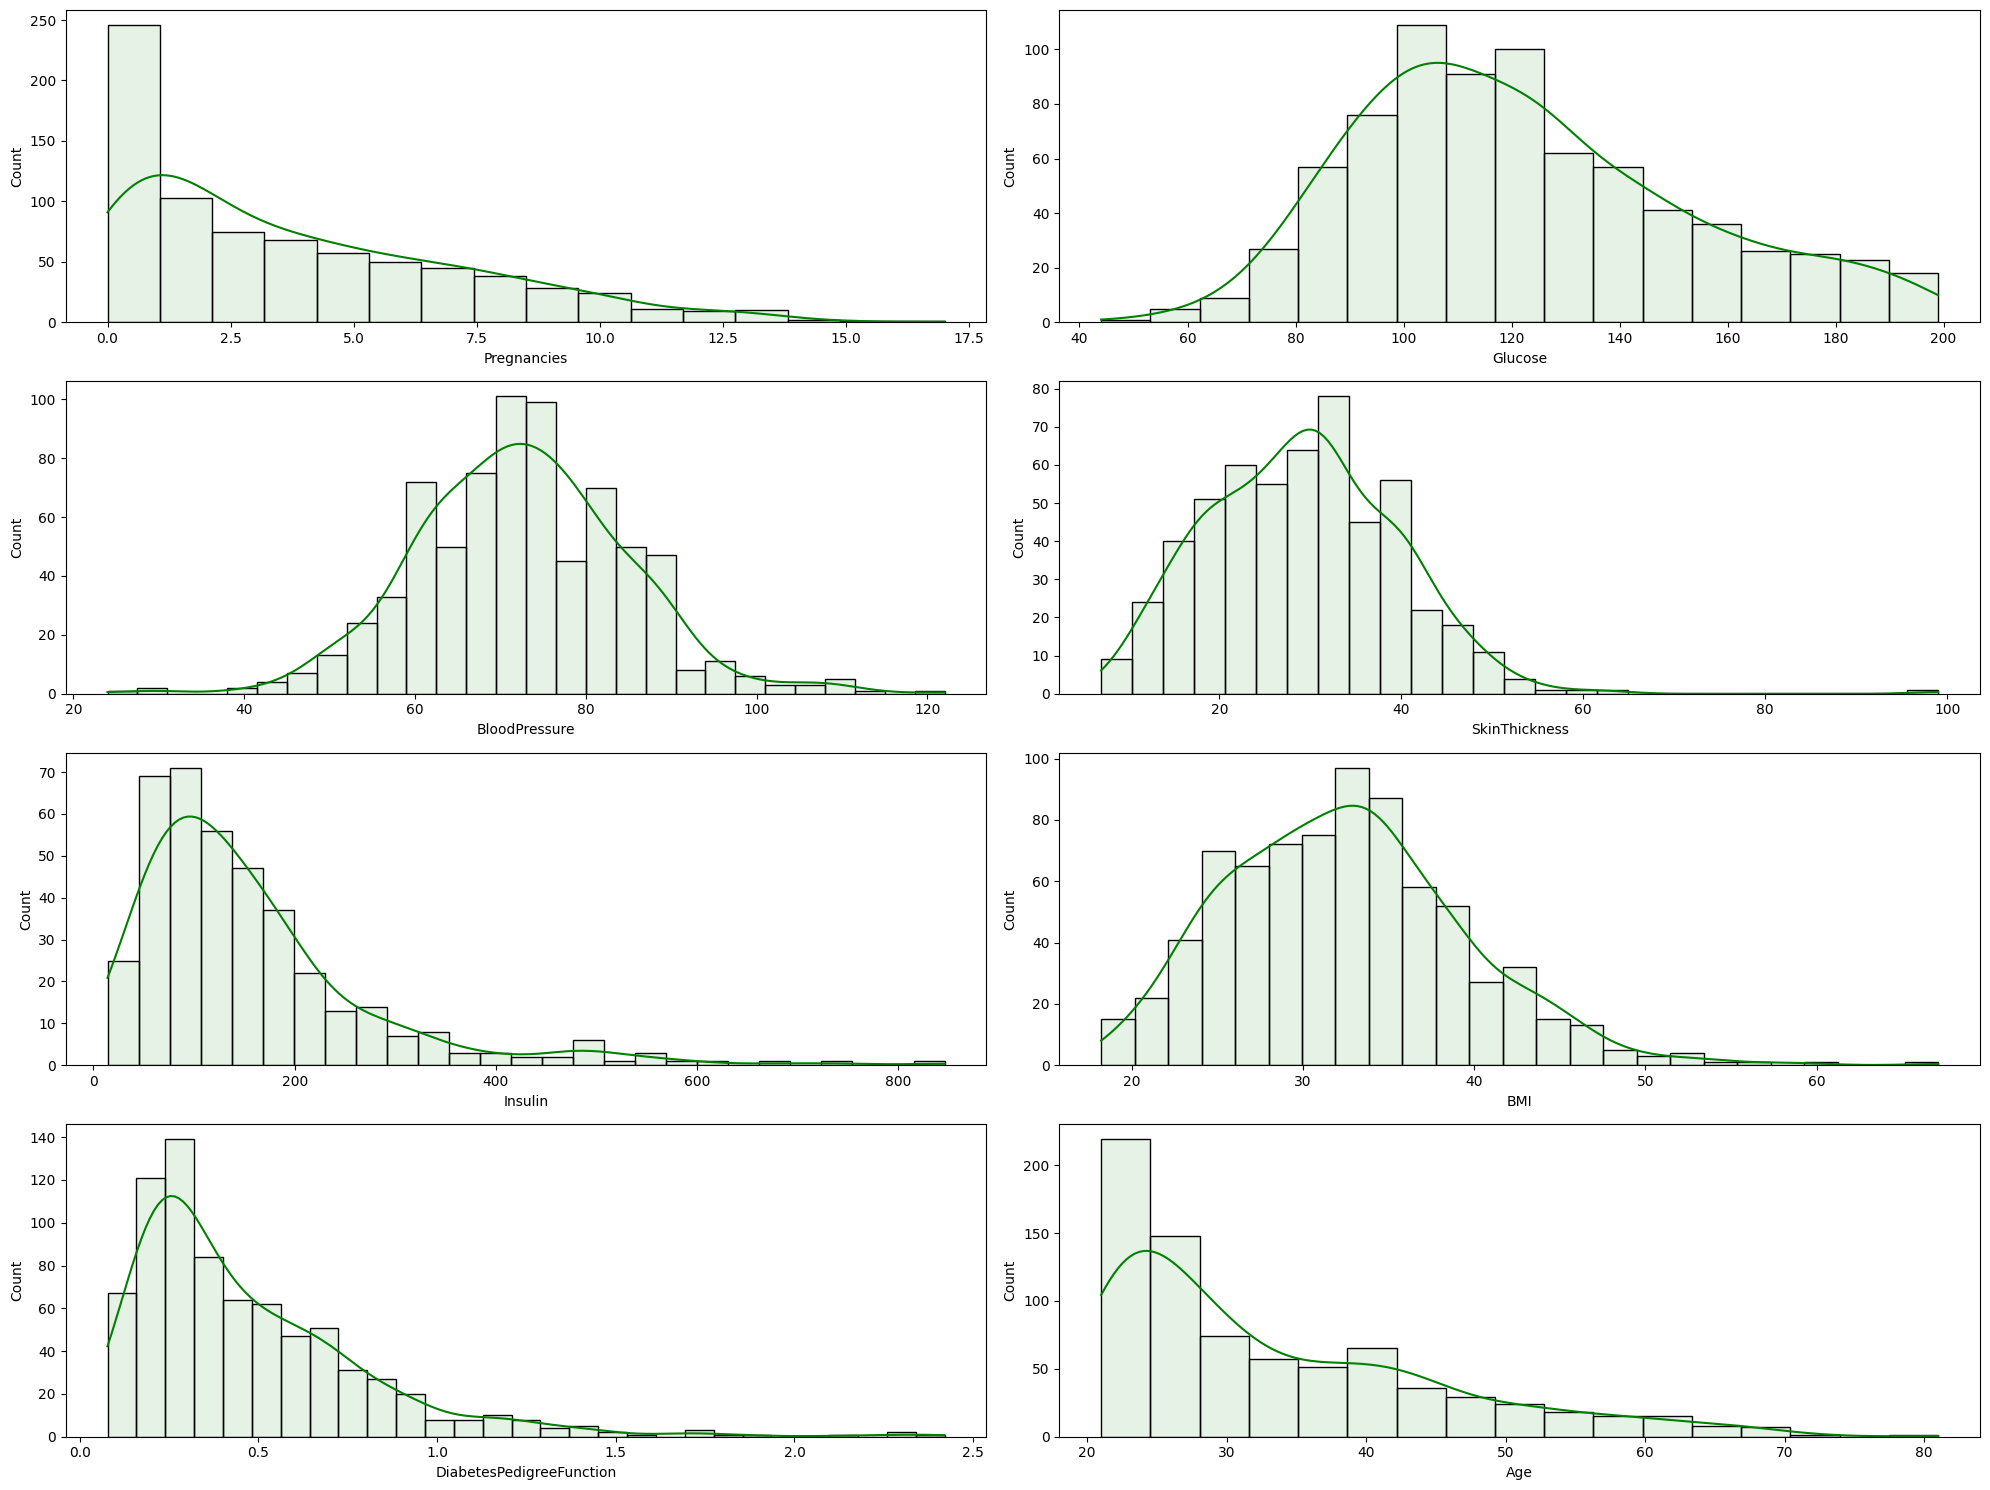

In [17]:
plt.figure(figsize=(20,15))

for idx,col in enumerate(columns):
    plt.subplot(4,2,idx+1)
    sns.histplot(data=df,x=col,kde=True,alpha=0.1,color="green")

plt.tight_layout()
plt.show()

In [18]:
df[columns].skew()

Pregnancies                 0.901674
Glucose                     0.530989
BloodPressure               0.134153
SkinThickness               0.690619
Insulin                     2.166464
BMI                         0.593970
DiabetesPedigreeFunction    1.919911
Age                         1.129597
dtype: float64

In [19]:
df.corr()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.128135,0.214178,0.100239,0.082171,0.021719,-0.033523,0.544341,0.221898
Glucose,0.128135,1.000000,0.223192,0.228043,0.581186,0.232771,0.137246,0.267136,0.494650
BloodPressure,0.214178,0.223192,1.000000,0.226839,0.098272,0.289230,-0.002805,0.330107,0.170589
SkinThickness,0.100239,0.228043,0.226839,1.000000,0.184888,0.648214,0.115016,0.166816,0.259491
Insulin,0.082171,0.581186,0.098272,0.184888,1.000000,0.228050,0.130395,0.220261,0.303454
BMI,0.021719,0.232771,0.289230,0.648214,0.228050,1.000000,0.155382,0.025841,0.313680
DiabetesPedigreeFunction,-0.033523,0.137246,-0.002805,0.115016,0.130395,0.155382,1.000000,0.033561,0.173844
Age,0.544341,0.267136,0.330107,0.166816,0.220261,0.025841,0.033561,1.000000,0.238356
Outcome,0.221898,0.494650,0.170589,0.259491,0.303454,0.313680,0.173844,0.238356,1.000000


<Axes: >

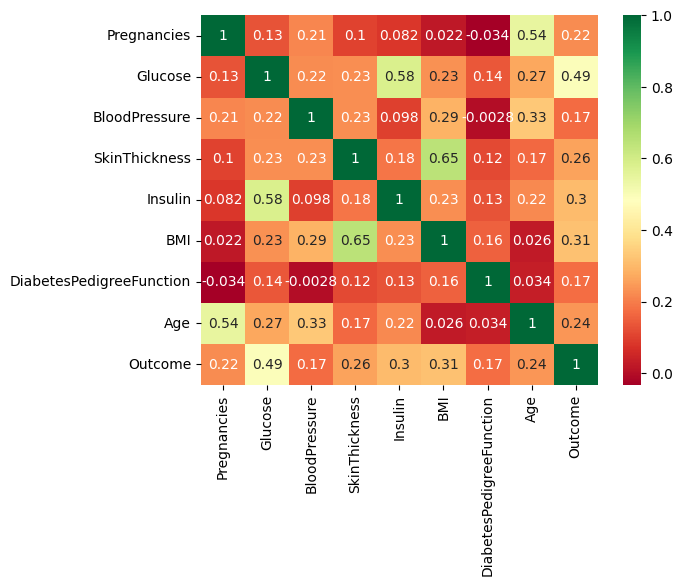

In [20]:
sns.heatmap(data=df.corr(),annot=True,cmap="RdYlGn")

**There is no multicolinearity in the dataset**

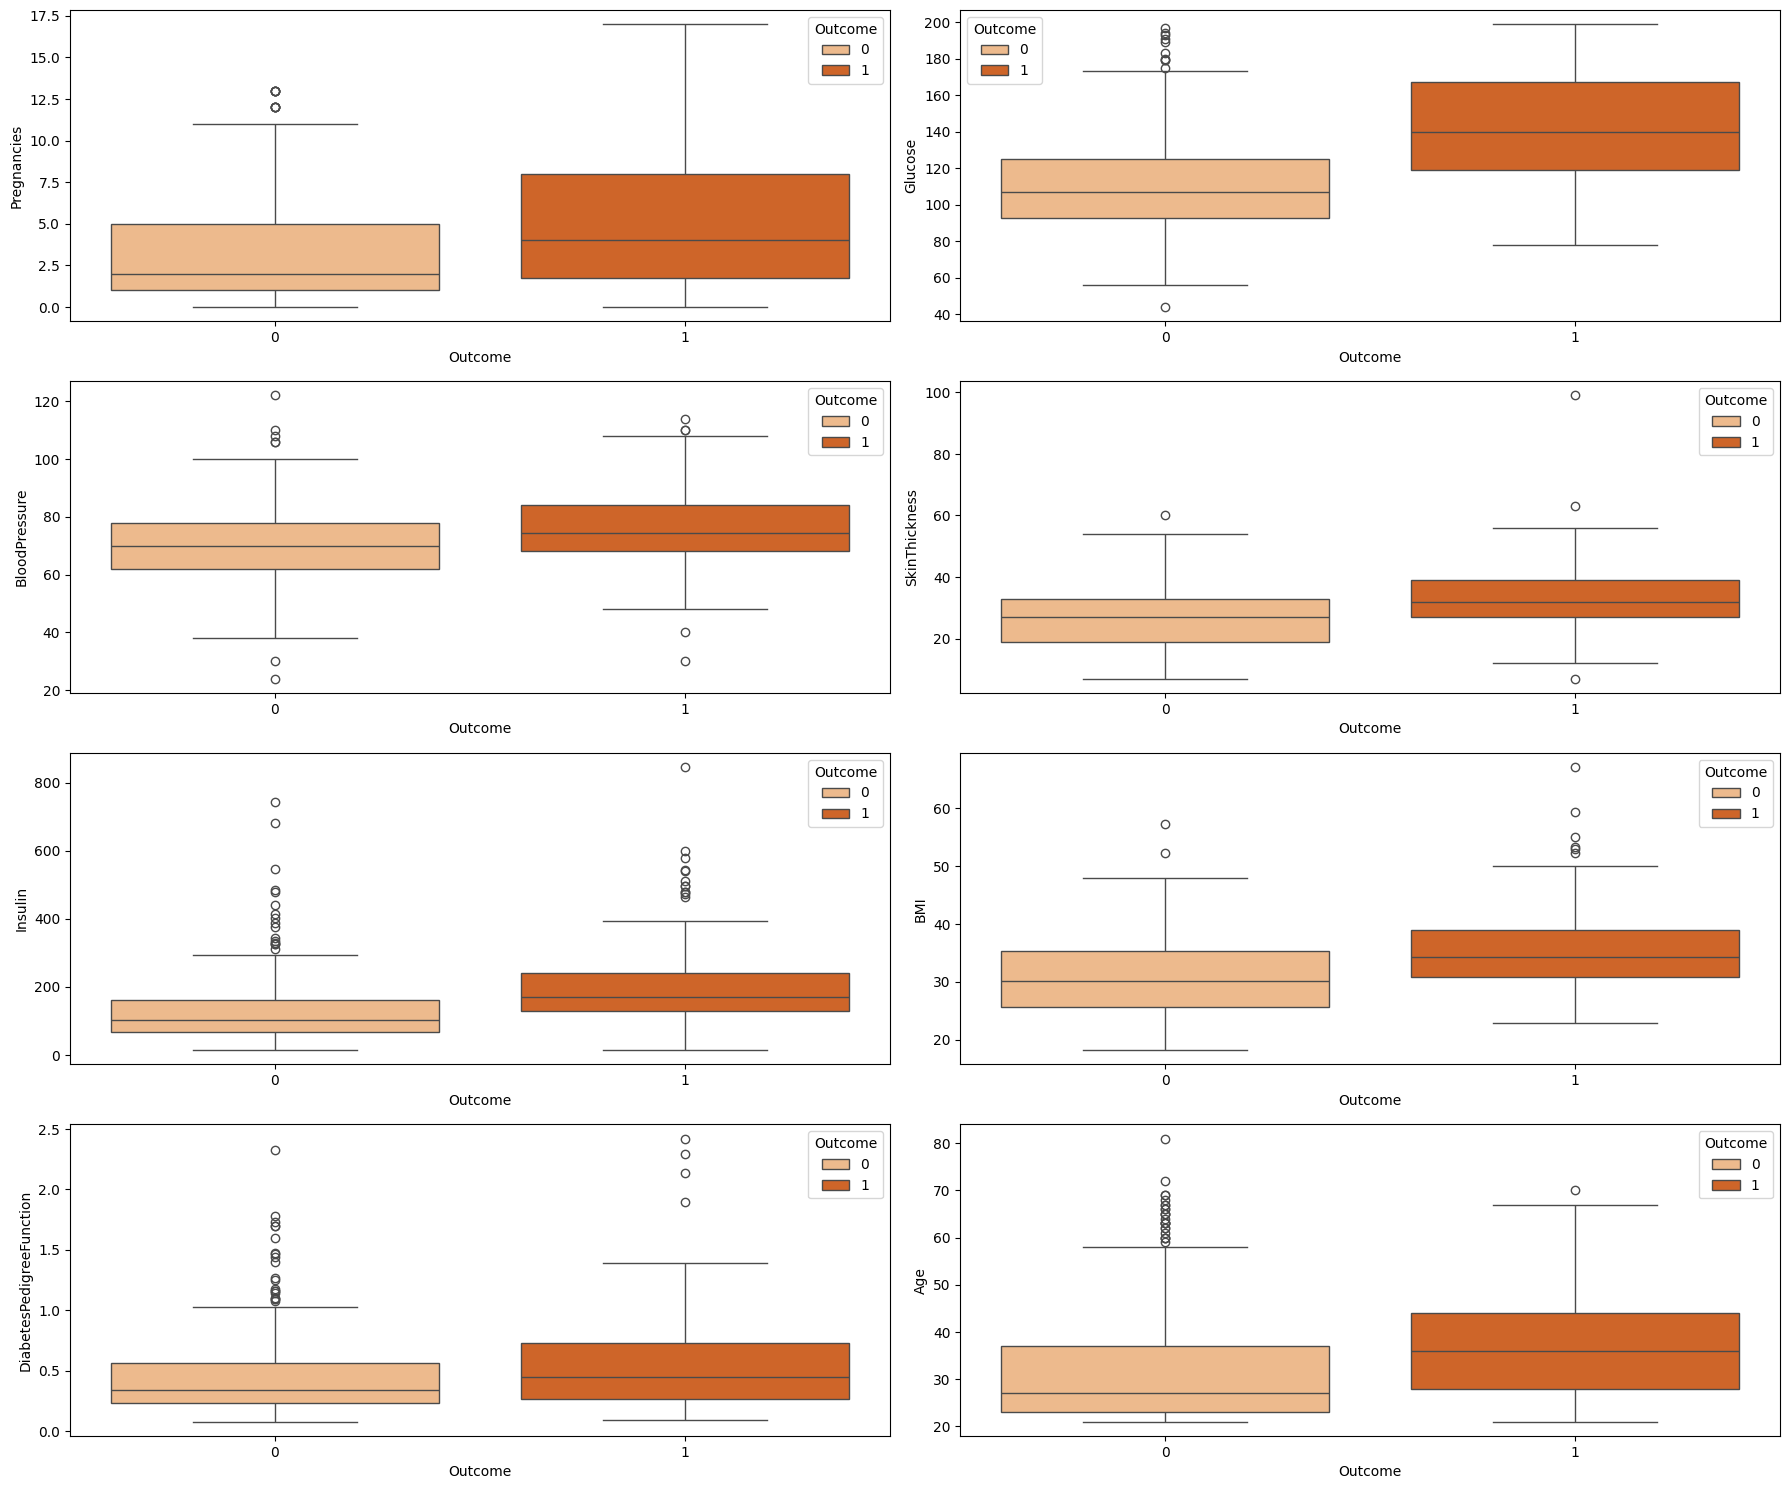

In [21]:
plt.figure(figsize=(18,15))
for idx,col in enumerate(columns):
    plt.subplot(4,2,idx+1)
    sns.boxplot(data=df,x="Outcome",y=col,hue="Outcome",palette="Oranges")

plt.tight_layout()
plt.show()

# Step-4: Outlier Detection & Handling

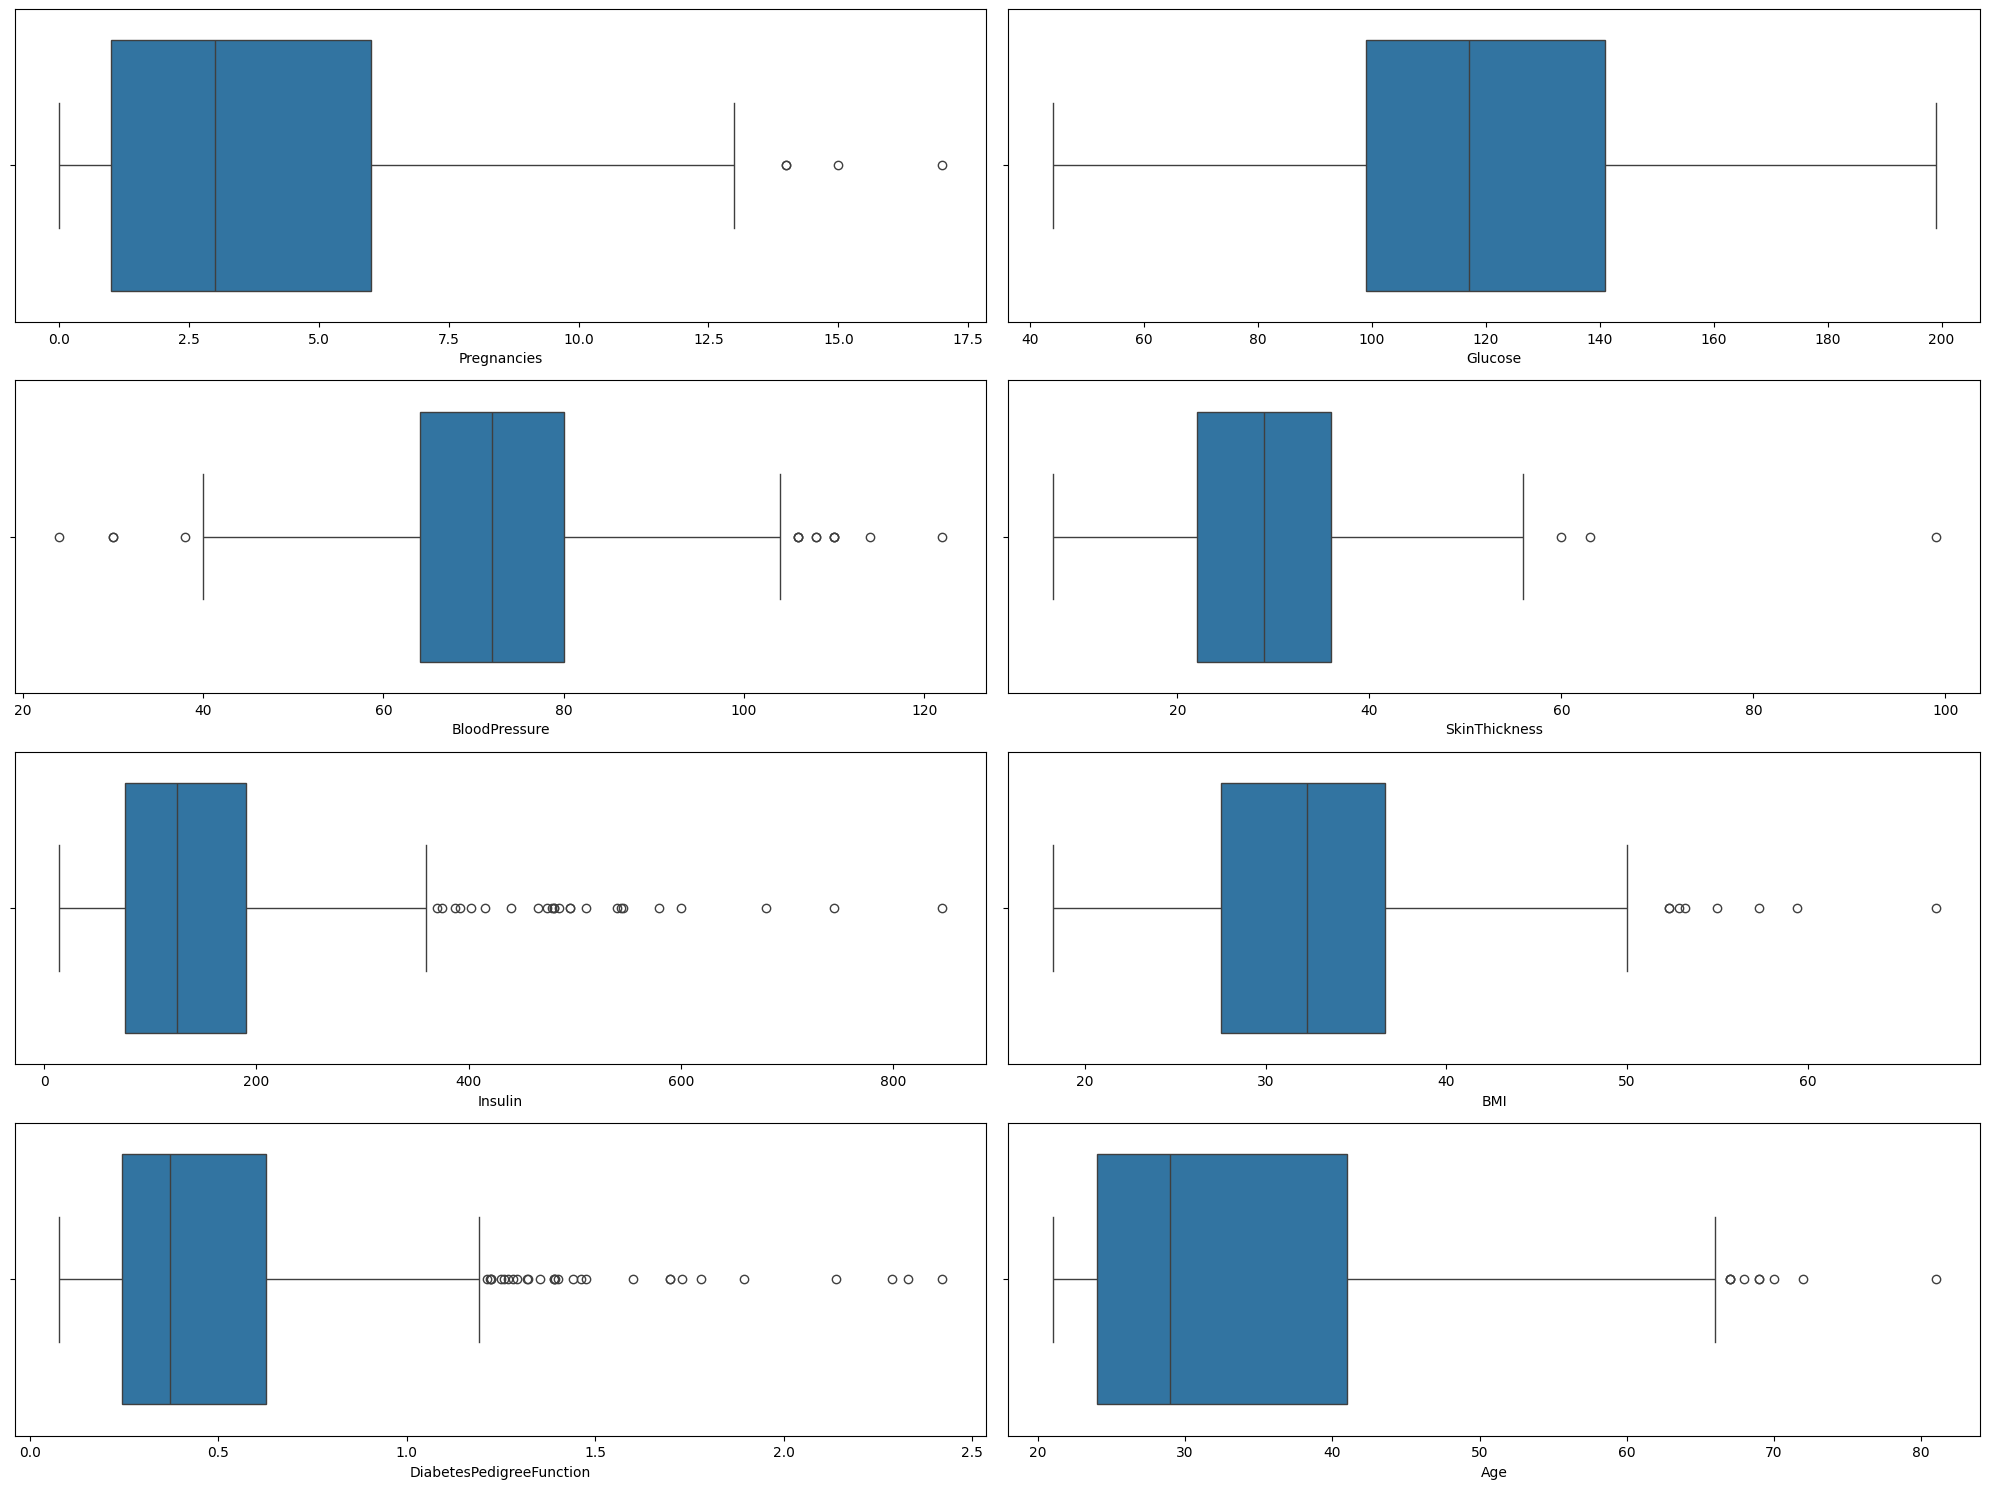

In [22]:
plt.figure(figsize=(20,15))

for idx,col in enumerate(columns):
    plt.subplot(4,2,idx+1)
    sns.boxplot(data=df,x=col)

plt.tight_layout()
plt.show()

In [23]:
for i in columns:
    Q1=df[i].quantile(0.25)
    Q3=df[i].quantile(0.75)
    IQR=Q3-Q1
    upper_bound=Q3+1.5*IQR
    lower_bound=Q1-1.5*IQR
    p=df[df[i]>upper_bound].shape[0]/df.shape[0]*100
    print(f"The {i} column has {p} % of data as outliers")
    df[i]=np.where(df[i]>upper_bound,upper_bound,np.where(df[i]<lower_bound,lower_bound,df[i]))

The Pregnancies column has 0.5208333333333333 % of data as outliers
The Glucose column has 0.0 % of data as outliers
The BloodPressure column has 1.3020833333333335 % of data as outliers
The SkinThickness column has 0.390625 % of data as outliers
The Insulin column has 3.125 % of data as outliers
The BMI column has 1.0416666666666665 % of data as outliers
The DiabetesPedigreeFunction column has 3.7760416666666665 % of data as outliers
The Age column has 1.171875 % of data as outliers


# Step-5: Train-Test Split

In [24]:
X_train,X_test,y_train,y_test=train_test_split(df.drop(columns=["Outcome"]),df["Outcome"],random_state=42,test_size=0.2)

print(X_train.shape[0])
print(X_test.shape[0])
print(y_train.shape[0])
print(y_test.shape[0])

614
154
614
154


# Step-6: Pipeline

In [25]:
columns

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age']

In [26]:
mean_features=['Glucose','BloodPressure']
median_features=['Pregnancies','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']

In [27]:
imputation_steps=ColumnTransformer(
    transformers=[
        ("impute_mean",SimpleImputer(strategy="mean"),mean_features),
        ("impute_median",SimpleImputer(strategy="median"),median_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

## Logistic Regression

In [28]:
ml_pipeline=Pipeline(
    steps=[
        ("imputation",imputation_steps),
        ("power_transform",PowerTransformer(method="yeo-johnson")),
        ("model",LogisticRegression())
    ]
)

In [29]:
ml_pipeline.fit(X_train,y_train)

Pipeline(steps=[('imputation',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('impute_mean',
                                                  SimpleImputer(),
                                                  ['Glucose', 'BloodPressure']),
                                                 ('impute_median',
                                                  SimpleImputer(strategy='median'),
                                                  ['Pregnancies',
                                                   'SkinThickness', 'Insulin',
                                                   'BMI',
                                                   'DiabetesPedigreeFunction',
                                                   'Age'])],
                                   verbose_feature_names_out=False)),
                ('power_transform', PowerTransformer()),
                ('model', LogisticRegression())])

In [30]:
y_pred=ml_pipeline.predict(X_test)

In [31]:
ac=accuracy_score(y_test,y_pred)
print(ac)

0.7597402597402597


In [32]:
cross_val1=cross_val_score(ml_pipeline,X_train,y_train,cv=5,scoring='accuracy')

In [33]:
cv1=np.mean(cross_val1)
print(cv1)

0.7703851792616286


### Example of Decision Boundary

In [34]:
X_train_2d=X_train[mean_features].values
y_train_arr=y_train.values.astype('int')

imputer = SimpleImputer(strategy='mean')
X_train_2d_clean = imputer.fit_transform(X_train_2d)

# 2. Build your pipeline with the REMAINING steps
model_2d = Pipeline(steps=[
    ('power_transform', PowerTransformer(method='yeo-johnson')),
    ('model', LogisticRegression())
])

# 3. Train the model on the clean data
model_2d.fit(X_train_2d_clean, y_train_arr)

Pipeline(steps=[('power_transform', PowerTransformer()),
                ('model', LogisticRegression())])

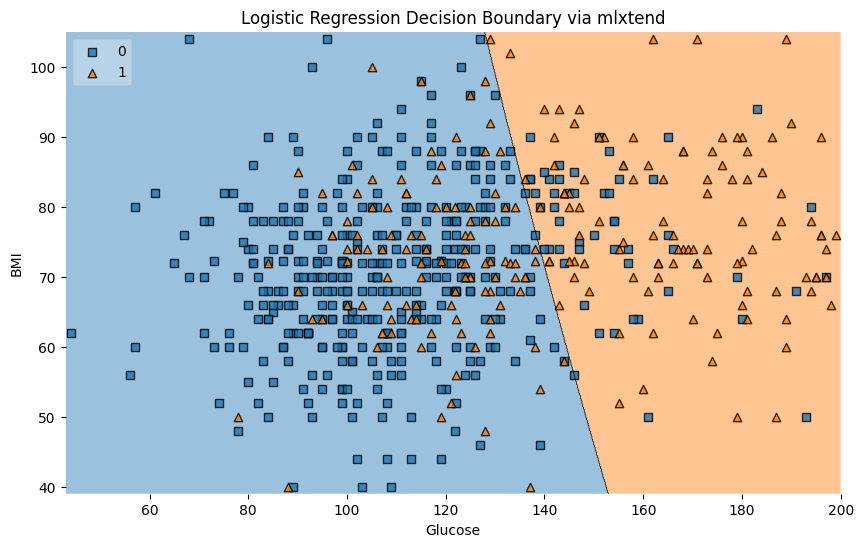

In [35]:
plt.figure(figsize=(10,6))

plot_decision_regions(X=X_train_2d_clean,y=y_train_arr,clf=model_2d,legend=2,colors='#1f77b4,#ff7f0e')

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Logistic Regression Decision Boundary via mlxtend')

plt.show()

## KNN 

In [36]:
ml_pipeline_kneighbors=Pipeline(
    steps=[
        ("imputation",imputation_steps),
        ("power_transform",PowerTransformer(method="yeo-johnson")),
        ("model",KNeighborsClassifier())
    ]
)


param_grid={'model__n_neighbors':[1,3,5,7,9,11,13,15,17,21]}
grid_search=GridSearchCV(
    estimator=ml_pipeline_kneighbors,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('imputation',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('impute_mean',
                                                                         SimpleImputer(),
                                                                         ['Glucose',
                                                                          'BloodPressure']),
                                                                        ('impute_median',
                                                                         SimpleImputer(strategy='median'),
                                                                         ['Pregnancies',
                                                                          'SkinThickness',
                                                                          'Insulin',
                                                                          'BMI',
                                                                          'DiabetesPedigreeFunction',
                                                                          'Age'])],
                                                          verbose_feature_names_out=False)),
                                       ('power_transform', PowerTransformer()),
                                       ('model', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'model__n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17,
                                                21]},
             scoring='accuracy', verbose=1)

In [37]:
print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation score: ", grid_search.best_score_)

Best parameters found:  {'model__n_neighbors': 17}
Best cross-validation score:  0.7753165400506463


In [38]:
cv2=grid_search.best_score_
print(cv2)

0.7753165400506463


# Step-6: Model Performance Analysis

<Axes: xlabel='Accuracy Score', ylabel='Model'>

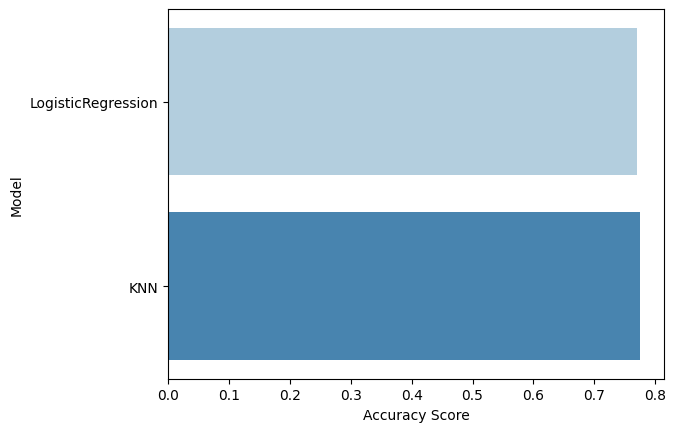

In [39]:
results=pd.DataFrame(
    {"LogisticRegression":[cv1],
    "KNN":[cv2]}
)


results=results.melt(var_name="Model",value_name="Accuracy Score")
results

sns.barplot(data=results,x="Accuracy Score",y="Model",hue="Model",palette="Blues")

**The Accuracy Score is almost similar with KNN getting the upper hand**

## Confusion Matrix

### Confusion Matrix for Logistic Regression

In [40]:
y_pred=ml_pipeline.predict(X_test)

In [41]:
pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'], margins=True)

Predicted,0,1,All
Actual,,,
0,81,18,99
1,19,36,55
All,100,54,154


Text(0.5, 1.1, 'Confusion matrix for Logistic Regression')

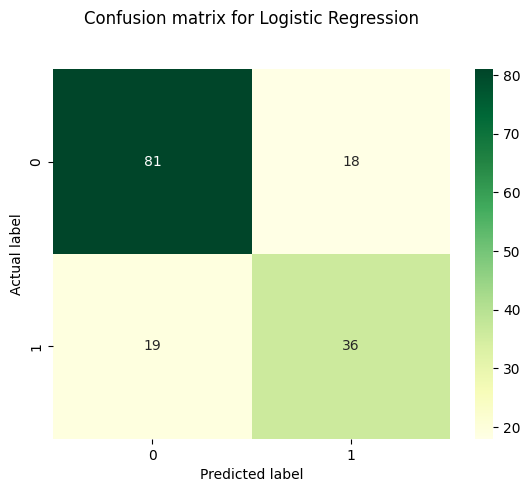

In [42]:

sns.heatmap(data=pd.DataFrame(confusion_matrix(y_test,y_pred)),annot=True,cmap="YlGn")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Confusion matrix for Logistic Regression', y=1.1)

### Confusion Matrix for KNN

In [43]:
y_pred1=grid_search.predict(X_test)

In [44]:
pd.crosstab(y_test, y_pred1, rownames=['Actual'], colnames=['Predicted'], margins=True)

Predicted,0,1,All
Actual,,,
0,80,19,99
1,22,33,55
All,102,52,154


Text(0.5, 1.1, 'Confusion matrix for KNN')

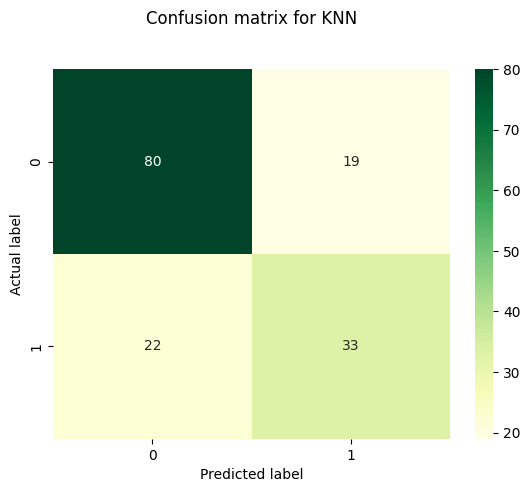

In [45]:
sns.heatmap(data=pd.DataFrame(confusion_matrix(y_test,y_pred1)),annot=True,cmap="YlGn")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Confusion matrix for KNN', y=1.1)

## Classification Report

In [46]:
print("=============================== Logistic Regression ================================")
print(classification_report(y_test,y_pred))

=============================== Logistic Regression ================================
              precision    recall  f1-score   support

           0       0.81      0.82      0.81        99
           1       0.67      0.65      0.66        55

    accuracy                           0.76       154
   macro avg       0.74      0.74      0.74       154
weighted avg       0.76      0.76      0.76       154



In [47]:
print("=============================== KNN ================================")
print(classification_report(y_test,y_pred1))

=============================== KNN ================================
              precision    recall  f1-score   support

           0       0.78      0.81      0.80        99
           1       0.63      0.60      0.62        55

    accuracy                           0.73       154
   macro avg       0.71      0.70      0.71       154
weighted avg       0.73      0.73      0.73       154



**The f1-score of Logistic Regression is coming out to be better than that of KNN.  So Logistic Regression should be more preferred model here**

## ROC-AUC

In [48]:
y_pred_probability=ml_pipeline.predict_proba(X_test)[:,1]
y_pred1_probability=grid_search.predict_proba(X_test)[:,1]
fpr1, tpr1, thresholds1 = roc_curve(y_test, y_pred_probability)
fpr2,tpr2,thresholds2=roc_curve(y_test,y_pred1_probability)

In [49]:
auc_lr=roc_auc_score(y_test,y_pred_probability)
auc_knn=roc_auc_score(y_test,y_pred1_probability)

print(f"The AUC for Logistic Regression is {auc_lr}")
print(f"The AUC for KNN is {auc_knn}")

The AUC for Logistic Regression is 0.8172635445362718
The AUC for KNN is 0.8150596877869606


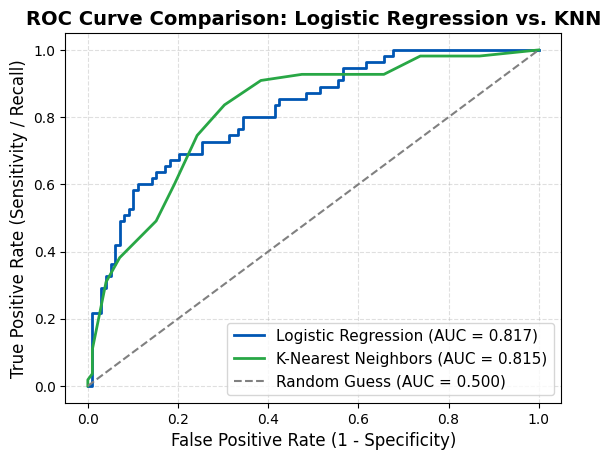

In [50]:
plt.plot(fpr1, tpr1, color='#0056b3', linewidth=2, 
         label=f'Logistic Regression (AUC = {auc_lr:.3f})')
plt.plot(fpr2, tpr2, color='#28a745', linewidth=2, 
         label=f'K-Nearest Neighbors (AUC = {auc_knn:.3f})')

# 6. Plot the "Random Guess" baseline (a diagonal line from 0,0 to 1,1)
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.500)')

# 7. Add labels, title, and grid
plt.title('ROC Curve Comparison: Logistic Regression vs. KNN', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.4, linestyle='--')

# 8. Show the plot
plt.show()